# 01_exploracao.ipynb — Análise Exploratória e Feature Engineering

**Projeto**: Predição de Readmissão Hospitalar 30 Dias (`readmission_30d`)

**Dataset**: Hospital Management Data (Kaggle) — 5 CSVs + 1 XLSX

**Alvo**: Classificação binária supervisionada com **Naive Bayes** (Scikit-Learn)

**Autor**: Patric — Disciplina Probabilidade e Estatística (IFCE)

---

## Objetivos deste Notebook

1. **Carregar e inspecionar** os 4 CSVs principais (`patients`, `visits_encounters`, `clinical_details`, `pharmacy_prescriptions`)
2. **Juntar tabelas** por `encounter_id` + `patient_id` → base unificada por encounter
3. **Feature Engineering**: agregações de pharmacy, bins de LOS, flags clínicas, `first_admission_flag`
4. **EDA completa** por bloco: Demografia, Internação, Clínico na Alta, Medicações
5. **Análise de missingness** e correlações com `readmission_30d`
6. **Definir lista final de features** (removendo vazamento: `discharge_disposition`, `icu_admitted`, `in_hospital_mortality`)
7. **Justificar** cada decisão em markdown para apresentação

---

## 1. Imports e Configuração

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

# Configurações
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Seed para reprodutibilidade (conforme CLAUDE.md)
RANDOM_STATE = 42

# Caminhos dos dados
DATA_DIR = Path('../data')
FILES = {
    'patients': 'patients.csv',
    'visits': 'visits_encounters.csv',
    'clinical': 'clinical_details.csv',
    'pharmacy': 'pharmacy_prescriptions.csv',
    'billing': 'hospital_billing.csv',  # não usado no modelo (vazamento)
}

for name, fname in FILES.items():
    path = DATA_DIR / fname
    print(f'{name:12s}: {path.exists()} — {path.stat().st_size/1e6:.1f} MB' if path.exists() else f'{name:12s}: NÃO ENCONTRADO')

patients    : True — 0.9 MB
visits      : True — 1.8 MB
clinical    : True — 2.7 MB
pharmacy    : True — 3.7 MB
billing     : True — 2.0 MB


## 2. Carregamento e Inspeção Inicial

In [26]:
# Carregar CSVs principais
patients = pd.read_csv(DATA_DIR / FILES['patients'])
visits = pd.read_csv(DATA_DIR / FILES['visits'])
clinical = pd.read_csv(DATA_DIR / FILES['clinical'])
pharmacy = pd.read_csv(DATA_DIR / FILES['pharmacy'])

print('=== SHAPES ===')
for name, df in [('patients', patients), ('visits', visits), ('clinical', clinical), ('pharmacy', pharmacy)]:
    print(f'{name:12s}: {df.shape[0]:>6,} linhas → {df.shape[1]:>2} colunas')

=== SHAPES ===
patients    :  5,000 linhas → 21 colunas
visits      : 13,214 linhas → 18 colunas
clinical    : 13,214 linhas → 22 colunas
pharmacy    : 26,715 linhas → 16 colunas


In [27]:
# Colunas de cada tabela
for name, df in [('patients', patients), ('visits', visits), ('clinical', clinical), ('pharmacy', pharmacy)]:
    print(f'\n=== {name.upper()} ({df.shape[1]} cols) ===')
    print(list(df.columns))


=== PATIENTS (21 cols) ===
['patient_id', 'first_name', 'last_name', 'gender', 'date_of_birth', 'age', 'blood_group', 'marital_status', 'race_ethnicity', 'residential_zone', 'socioeconomic_tier', 'primary_insurance_provider', 'insurance_policy_id', 'contact_phone', 'emergency_contact_phone', 'street_address', 'zip_code', 'baseline_bmi', 'smoker_status', 'baseline_charlson_comorbidity_index', 'registration_date']

=== VISITS (18 cols) ===
['encounter_id', 'patient_id', 'encounter_type', 'admission_datetime', 'discharge_datetime', 'length_of_stay_days', 'admission_urgency', 'department', 'attending_physician_id', 'icu_admitted', 'icu_days', 'discharge_disposition', 'news2_acuity_score', 'revisit_count', 'previous_encounter_id', 'days_since_last_discharge', 'readmission_30d', 'in_hospital_mortality']

=== CLINICAL (22 cols) ===
['clinical_record_id', 'encounter_id', 'patient_id', 'primary_diagnosis_code', 'primary_diagnosis_name', 'disease_category', 'disease_severity', 'secondary_diagno

In [28]:
# Head + dtypes + nulos → patients
print('=== PATIENTS ===')
display(patients.head(3))
print('\nDtypes:')
print(patients.dtypes)
print('\nNulos (%):')
print((patients.isnull().mean() * 100).round(2).sort_values(ascending=False))

=== PATIENTS ===


,patient_id,first_name,last_name,gender,date_of_birth,age,blood_group,marital_status,race_ethnicity,residential_zone,socioeconomic_tier,primary_insurance_provider,insurance_policy_id,contact_phone,emergency_contact_phone,street_address,zip_code,baseline_bmi,smoker_status,baseline_charlson_comorbidity_index,registration_date
0,PAT-10001,Mark,Johnson,Male,1945-11-05,77,O+,Married,Hispanic,Suburban,High,Medicare,INS-887201,533-521-8196x001,790.683.8637x94026,51161 Abbott Rapids,35172,35.7,Former,1,2021-10-02
1,PAT-10002,Renee,Blair,Female,1982-12-16,40,B-,Married,Caucasian,Suburban,Middle,Self-Pay,NaN,+1-516-318-4959,NaN,3419 Amanda Gardens Apt. 764,84387,30.0,Never,3,2021-08-24
2,PAT-10003,Melissa,Robinson,Female,2004-10-09,18,O+,Single,African American,Suburban,Middle,BlueCross,INS-560337,903-405-6413x95376,423-988-4969x653,12269 Paul Ranch,61849,21.1,Never,1,2021-05-30



Dtypes:
patient_id                                 str
first_name                                 str
last_name                                  str
gender                                     str
date_of_birth                              str
age                                      int64
blood_group                                str
marital_status                             str
race_ethnicity                             str
residential_zone                           str
socioeconomic_tier                         str
primary_insurance_provider                 str
insurance_policy_id                        str
contact_phone                              str
emergency_contact_phone                    str
street_address                             str
zip_code                                 int64
baseline_bmi                           float64
smoker_status                              str
baseline_charlson_comorbidity_index      int64
registration_date                          str
dtyp

In [29]:
# Head + dtypes + nulos → visits_encounters
print('=== VISITS_ENCOUNTERS ===')
display(visits.head(3))
print('\nDtypes:')
print(visits.dtypes)
print('\nNulos (%):')
print((visits.isnull().mean() * 100).round(2).sort_values(ascending=False))

=== VISITS_ENCOUNTERS ===


,encounter_id,patient_id,encounter_type,admission_datetime,discharge_datetime,length_of_stay_days,admission_urgency,department,attending_physician_id,icu_admitted,icu_days,discharge_disposition,news2_acuity_score,revisit_count,previous_encounter_id,days_since_last_discharge,readmission_30d,in_hospital_mortality
0,ENC-100001,PAT-10001,Emergency,2023-03-30 00:00:00,2023-04-03 07:12:00,4.30,Emergency,General Medicine,DOC-106,0,0.0,Skilled Nursing Facility,1,1,NaN,NaN,0,0
1,ENC-100002,PAT-10001,Outpatient,2023-04-06 12:00:00,2023-04-06 16:19:12,0.18,Elective,General Medicine,DOC-151,0,0.0,Home,2,2,ENC-100001,3.2,0,0
2,ENC-100003,PAT-10001,Outpatient,2023-04-18 04:19:12,2023-04-18 13:55:12,0.40,Elective,Cardiology,DOC-111,0,0.0,Home,9,3,ENC-100002,11.5,1,0



Dtypes:
encounter_id                     str
patient_id                       str
encounter_type                   str
admission_datetime               str
discharge_datetime               str
length_of_stay_days          float64
admission_urgency                str
department                       str
attending_physician_id           str
icu_admitted                   int64
icu_days                     float64
discharge_disposition            str
news2_acuity_score             int64
revisit_count                  int64
previous_encounter_id            str
days_since_last_discharge    float64
readmission_30d                int64
in_hospital_mortality          int64
dtype: object

Nulos (%):
days_since_last_discharge    37.84
previous_encounter_id        37.84
attending_physician_id        5.59
discharge_disposition         5.34
patient_id                    0.00
encounter_id                  0.00
length_of_stay_days           0.00
encounter_type                0.00
discharge_datetime 

In [30]:
# Head + dtypes + nulos → clinical_details
print('=== CLINICAL_DETAILS ===')
display(clinical.head(3))
print('\nDtypes:')
print(clinical.dtypes)
print('\nNulos (%):')
print((clinical.isnull().mean() * 100).round(2).sort_values(ascending=False))

=== CLINICAL_DETAILS ===


,clinical_record_id,encounter_id,patient_id,primary_diagnosis_code,primary_diagnosis_name,disease_category,disease_severity,secondary_diagnosis_code,systolic_bp_mmhg,diastolic_bp_mmhg,heart_rate_bpm,respiratory_rate_bpm,temperature_celsius,spo2_percent,blood_glucose_mg_dl,serum_creatinine_mg_dl,hemoglobin_g_dl,white_blood_cell_count,primary_procedure_code,primary_procedure_name,procedure_complexity,hospital_acquired_infection
0,CLN-100001,ENC-100001,PAT-10001,N39.0,Urinary Tract Infection with Pyelonephritis,Renal,Mild,E78.5,119.7,78.9,67.3,16.7,36.6,99.6,116.2,1.17,NaN,4.5,99221,Inpatient Bladder Management & Culture Evaluation,NaN,0
1,CLN-100002,ENC-100002,PAT-10001,J44.1,COPD with Acute Exacerbation,Respiratory,Moderate,N18.3,118.5,86.2,74.4,18.0,37.2,97.9,98.0,0.71,14.4,6.8,94660,Continuous Positive Airway Pressure (CPAP) Man...,Minor,0
2,CLN-100003,ENC-100003,PAT-10001,I50.9,"Congestive Heart Failure, Unspecified",Cardiovascular,Severe,E78.5,129.0,87.2,98.7,15.2,36.7,98.8,118.5,2.89,15.1,25.9,99223,Comprehensive Inpatient Medical Management,NaN,0



Dtypes:
clinical_record_id                 str
encounter_id                       str
patient_id                         str
primary_diagnosis_code             str
primary_diagnosis_name             str
disease_category                   str
disease_severity                   str
secondary_diagnosis_code           str
systolic_bp_mmhg               float64
diastolic_bp_mmhg              float64
heart_rate_bpm                 float64
respiratory_rate_bpm           float64
temperature_celsius            float64
spo2_percent                   float64
blood_glucose_mg_dl            float64
serum_creatinine_mg_dl         float64
hemoglobin_g_dl                float64
white_blood_cell_count         float64
primary_procedure_code           int64
primary_procedure_name             str
procedure_complexity               str
hospital_acquired_infection      int64
dtype: object

Nulos (%):
procedure_complexity           42.79
blood_glucose_mg_dl             6.23
white_blood_cell_count          6

In [31]:
# Head + dtypes + nulos → pharmacy_prescriptions
print('=== PHARMACY_PRESCRIPTIONS ===')
display(pharmacy.head(3))
print('\nDtypes:')
print(pharmacy.dtypes)
print('\nNulos (%):')
print((pharmacy.isnull().mean() * 100).round(2).sort_values(ascending=False))

=== PHARMACY_PRESCRIPTIONS ===


,pharmacy_order_id,encounter_id,patient_id,ndc_code,drug_name,therapeutic_class,dosage_form,dose_strength,administration_frequency,days_supply,quantity_dispensed,unit_cost_usd,total_drug_cost,insurance_covered_drug_cost,patient_copay_drug_cost,high_risk_medication_flag
0,RX-100001,ENC-100001,PAT-10001,87500-521-28,Ceftriaxone 1g IV,Cephalosporin Antibiotic,IV Infusion,1 g,QD,4,4,20.89,83.56,68.52,15.04,0
1,RX-100002,ENC-100001,PAT-10001,91030-751-41,Nitrofurantoin 100mg,Antibacterial,NaN,100 mg,BID,4,8,1.11,8.88,7.28,1.60,0
2,RX-100003,ENC-100001,PAT-10001,30420-438-16,Phenazopyridine 100mg,Urinary Analgesic,Oral Tablet,100 mg,TID,4,12,0.69,8.28,6.79,1.49,0



Dtypes:
pharmacy_order_id                  str
encounter_id                       str
patient_id                         str
ndc_code                           str
drug_name                          str
therapeutic_class                  str
dosage_form                        str
dose_strength                      str
administration_frequency           str
days_supply                      int64
quantity_dispensed               int64
unit_cost_usd                  float64
total_drug_cost                float64
insurance_covered_drug_cost    float64
patient_copay_drug_cost        float64
high_risk_medication_flag        int64
dtype: object

Nulos (%):
dosage_form                    5.15
pharmacy_order_id              0.00
patient_id                     0.00
encounter_id                   0.00
ndc_code                       0.00
drug_name                      0.00
therapeutic_class              0.00
dose_strength                  0.00
administration_frequency       0.00
days_supply      

## 3. Verificação de Chaves de Junção

As 4 tabelas principais têm `encounter_id` e `patient_id`. Vamos confirmar cardinalidade e unicidade.

In [32]:
# Verificar chaves
print('=== UNICIDADE ===')
print(f'patients.patient_id único: {patients["patient_id"].nunique()} / {len(patients)} = {patients["patient_id"].nunique()/len(patients):.2%}')
print(f'visits.encounter_id único: {visits["encounter_id"].nunique()} / {len(visits)} = {visits["encounter_id"].nunique()/len(visits):.2%}')
print(f'clinical.encounter_id único: {clinical["encounter_id"].nunique()} / {len(clinical)} = {clinical["encounter_id"].nunique()/len(clinical):.2%}')
print(f'pharmacy.encounter_id únicos: {pharmacy["encounter_id"].nunique()} / {len(pharmacy)} linhas')

# Quantos encounters por paciente em pharmacy
pharmacy_enc_counts = pharmacy.groupby('encounter_id').size()
print(f'\nPrescrições por encounter: média={pharmacy_enc_counts.mean():.1f}, max={pharmacy_enc_counts.max()}, min={pharmacy_enc_counts.min()}')

=== UNICIDADE ===
patients.patient_id único: 5000 / 5000 = 100.00%
visits.encounter_id único: 13214 / 13214 = 100.00%
clinical.encounter_id único: 13214 / 13214 = 100.00%
pharmacy.encounter_id únicos: 13214 / 26715 linhas

Prescrições por encounter: média=2.0, max=3, min=1


## 4. Juntar Tabelas → Base Unificada por Encounter

Estratégia: `visits` é o nó central (1 linha por encounter). Juntamos `patients` por `patient_id`, `clinical` por `encounter_id` (pegando o último registro por encounter = estado na alta), e agregamos `pharmacy` por `encounter_id`.

In [33]:
# 4.1 Clinical: um registro por encounter (o CSV não possui recorded_at)
# Se houver múltiplas medições em outra versão do arquivo, usa a mais recente.
if 'recorded_at' in clinical.columns:
    clinical_latest = (
        clinical.assign(recorded_at=pd.to_datetime(clinical['recorded_at'], errors='coerce'))
        .sort_values('recorded_at')
        .groupby('encounter_id', as_index=False)
        .tail(1)
    )
else:
    clinical_latest = clinical.copy()

# Padronizar nomes clínicos usados nas etapas de features.
clinical_latest = clinical_latest.rename(columns={
    'systolic_bp_mmhg': 'systolic_bp',
    'diastolic_bp_mmhg': 'diastolic_bp',
    'heart_rate_bpm': 'heart_rate',
    'respiratory_rate_bpm': 'respiratory_rate',
    'temperature_celsius': 'temperature',
    'spo2_percent': 'spo2',
    'blood_glucose_mg_dl': 'glucose',
    'serum_creatinine_mg_dl': 'creatinine',
    'hemoglobin_g_dl': 'hemoglobin',
    'white_blood_cell_count': 'wbc_count',
})
print(f'clinical_latest shape: {clinical_latest.shape}')

# 4.2 Pharmacy: agregar por encounter
# O arquivo contém apenas high_risk_medication_flag; as demais flags são
# derivadas do nome/classe do medicamento.
pharmacy_work = pharmacy.copy()
drug_text = (pharmacy_work['drug_name'].fillna('') + ' ' +
             pharmacy_work['therapeutic_class'].fillna('')).str.lower()
pharmacy_work['is_anticoagulant'] = drug_text.str.contains(
    r'anticoagul|heparin|warfarin|apixaban|rivaroxaban|dabigatran', regex=True
).astype(int)
pharmacy_work['is_insulin'] = drug_text.str.contains(
    r'insulin', regex=True
).astype(int)
pharmacy_work['is_diuretic'] = drug_text.str.contains(
    r'diuretic|furosemide|hydrochlorothiazide|spironolactone', regex=True
).astype(int)
pharmacy_work['is_beta_blocker'] = drug_text.str.contains(
    r'beta.blocker|metoprolol|propranolol|atenolol|carvedilol', regex=True
).astype(int)
pharmacy_work['is_ace_arb'] = drug_text.str.contains(
    r'ace inhibitor|arb|lisinopril|enalapril|losartan|valsartan', regex=True
).astype(int)
pharmacy_agg = pharmacy_work.groupby('encounter_id').agg(
    num_medications=('ndc_code', 'nunique'),
    num_therapeutic_classes=('therapeutic_class', 'nunique'),
    has_high_risk_med=('high_risk_medication_flag', 'max'),
    has_anticoagulant=('is_anticoagulant', 'max'),
    has_insulin=('is_insulin', 'max'),
    has_diuretic=('is_diuretic', 'max'),
    has_beta_blocker=('is_beta_blocker', 'max'),
    has_ace_arb=('is_ace_arb', 'max'),
).reset_index()
print(f'pharmacy_agg shape: {pharmacy_agg.shape}')

# 4.3 Juntar tudo: visits (base) + patients + clinical_latest + pharmacy_agg
df = visits.merge(patients, on='patient_id', how='left')
df = df.merge(clinical_latest, on='encounter_id', how='left', suffixes=('', '_clin'))
df = df.merge(pharmacy_agg, on='encounter_id', how='left')

print(f'Base unificada shape: {df.shape}')
print(f'Colunas: {list(df.columns)}')

clinical_latest shape: (13214, 22)
pharmacy_agg shape: (13214, 9)
Base unificada shape: (13214, 67)
Colunas: ['encounter_id', 'patient_id', 'encounter_type', 'admission_datetime', 'discharge_datetime', 'length_of_stay_days', 'admission_urgency', 'department', 'attending_physician_id', 'icu_admitted', 'icu_days', 'discharge_disposition', 'news2_acuity_score', 'revisit_count', 'previous_encounter_id', 'days_since_last_discharge', 'readmission_30d', 'in_hospital_mortality', 'first_name', 'last_name', 'gender', 'date_of_birth', 'age', 'blood_group', 'marital_status', 'race_ethnicity', 'residential_zone', 'socioeconomic_tier', 'primary_insurance_provider', 'insurance_policy_id', 'contact_phone', 'emergency_contact_phone', 'street_address', 'zip_code', 'baseline_bmi', 'smoker_status', 'baseline_charlson_comorbidity_index', 'registration_date', 'clinical_record_id', 'patient_id_clin', 'primary_diagnosis_code', 'primary_diagnosis_name', 'disease_category', 'disease_severity', 'secondary_diagno

## 5. Feature Engineering

Criar features derivadas baseadas no conhecimento de domínio e no dicionário de dados do Kaggle.

In [34]:
# 5.1 Features demográficas derivadas
df['is_elderly'] = (df['age'] >= 65).astype(int)

# 5.2 Features de internação derivadas
df['los_category'] = pd.cut(df['length_of_stay_days'], 
                             bins=[-1, 1, 3, 7, 60], 
                             labels=['0-1', '2-3', '4-7', '8+'])
df['first_admission_flag'] = df['days_since_last_discharge'].isna().astype(int)

# 5.3 Features de medicação derivadas
df['polypharmacy_flag'] = (df['num_medications'] >= 5).astype(int)

# 5.4 Preencher nulos de pharmacy (encounters sem prescrição)
pharm_cols = ['num_medications', 'num_therapeutic_classes', 'has_high_risk_med',
              'has_anticoagulant', 'has_insulin', 'has_diuretic',
              'has_beta_blocker', 'has_ace_arb', 'polypharmacy_flag']
for c in pharm_cols:
    if c in df.columns:
        df[c] = df[c].fillna(0)

print('Features derivadas criadas.')
print(df[['is_elderly', 'los_category', 'first_admission_flag', 'polypharmacy_flag']].head())

Features derivadas criadas.
   is_elderly los_category  first_admission_flag  polypharmacy_flag
0           1          4-7                     1                  0
1           1          0-1                     0                  0
2           1          0-1                     0                  0
3           0           8+                     1                  0
4           0          4-7                     0                  0


## 6. Variável-Alvo: `readmission_30d`

Confirmar que a coluna existe em `visits` (foi trazida no merge) e analisar distribuição.

In [35]:
# Verificar target
print('Target em df.columns:', 'readmission_30d' in df.columns)
if 'readmission_30d' in df.columns:
    print('\nDistribuição:')
    print(df['readmission_30d'].value_counts())
    print('\nProporção:')
    print(df['readmission_30d'].value_counts(normalize=True).round(4))
    print(f'\nMissing: {df["readmission_30d"].isna().sum()}')

Target em df.columns: True

Distribuição:
readmission_30d
0    8850
1    4364
Name: count, dtype: int64

Proporção:
readmission_30d
0    0.6697
1    0.3303
Name: proportion, dtype: float64

Missing: 0


## 7. Remover Features com Vazamento (Data Leakage)

Identificar e remover colunas que só existem **após** o resultado que queremos prever (readmissão em 30 dias).

**Colunas a remover (vazamento direto):**
- `discharge_disposition` — só se sabe na alta; determina se foi para casa, transferido, óbito, etc.
- `icu_admitted` — só se sabe durante/ao final da internação
- `in_hospital_mortality` — é o óbito *durante* a internação (mutuamente exclusivo com readmissão)
- `total_charges`, `total_costs`, `insurance_payout` — billing (só após alta)
- `encounter_id`, `patient_id` — identificadores
- `recorded_at` (de clinical) — timestamp da medição
- `admission_date`, `discharge_date` — datas brutas (usamos `length_of_stay_days` derivado)


In [36]:
# Colunas a remover
leak_cols = [
    'discharge_disposition', 'icu_admitted', 'in_hospital_mortality',
    'total_charges', 'total_costs', 'insurance_payout',
    'encounter_id', 'patient_id',
    'recorded_at', 'admission_date', 'discharge_date'
]

existing_leak = [c for c in leak_cols if c in df.columns]
print(f'Removendo {len(existing_leak)} colunas de vazamento: {existing_leak}')

df_model = df.drop(columns=existing_leak)
print(f'Shape após remoção: {df_model.shape}')

Removendo 5 colunas de vazamento: ['discharge_disposition', 'icu_admitted', 'in_hospital_mortality', 'encounter_id', 'patient_id']
Shape após remoção: (13214, 66)


## 8. Definição Final de Features e Tipos

Separar features por tipo para o ColumnTransformer.

In [37]:
# Separar target
y = df_model['readmission_30d']
X = df_model.drop(columns=['readmission_30d'])

# Identificar tipos
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f'Numéricas ({len(numeric_cols)}): {numeric_cols}')
print(f'Categóricas ({len(categorical_cols)}): {categorical_cols}')

Numéricas (32): ['length_of_stay_days', 'icu_days', 'news2_acuity_score', 'revisit_count', 'days_since_last_discharge', 'age', 'zip_code', 'baseline_bmi', 'baseline_charlson_comorbidity_index', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'respiratory_rate', 'temperature', 'spo2', 'glucose', 'creatinine', 'hemoglobin', 'wbc_count', 'primary_procedure_code', 'hospital_acquired_infection', 'num_medications', 'num_therapeutic_classes', 'has_high_risk_med', 'has_anticoagulant', 'has_insulin', 'has_diuretic', 'has_beta_blocker', 'has_ace_arb', 'is_elderly', 'first_admission_flag', 'polypharmacy_flag']
Categóricas (33): ['encounter_type', 'admission_datetime', 'discharge_datetime', 'admission_urgency', 'department', 'attending_physician_id', 'previous_encounter_id', 'first_name', 'last_name', 'gender', 'date_of_birth', 'blood_group', 'marital_status', 'race_ethnicity', 'residential_zone', 'socioeconomic_tier', 'primary_insurance_provider', 'insurance_policy_id', 'contact_phone', 'emergency_c

In [38]:
# Verificar nulos por coluna
nulls = X.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(f'Colunas com nulos ({len(nulls)}):')
print(nulls)
print(f'\nTotal nulos: {X.isnull().sum().sum()}')

Colunas com nulos (15):
procedure_complexity         5654
days_since_last_discharge    5000
previous_encounter_id        5000
insurance_policy_id           987
baseline_bmi                  843
glucose                       823
emergency_contact_phone       816
wbc_count                     802
secondary_diagnosis_code      791
contact_phone                 762
creatinine                    755
spo2                          755
attending_physician_id        739
hemoglobin                    674
smoker_status                 647
dtype: int64

Total nulos: 25048


## 9. EDA por Bloco de Features

Analisar distribuição e relação com o target para cada grupo de features.

### 9.1 Demografia e Comorbidades Basais

In [39]:
demo_cols = ['age', 'is_elderly', 'gender', 'charlson_comorbidity_index', 'bmi',
             'smoker_status', 'socioeconomic_tier', 'residential_zone', 'marital_status']
demo_cols = [c for c in demo_cols if c in X.columns]

print('=== ESTATÍSTICAS DESCRITIVAS ===')
print(X[demo_cols].describe(include='all').T)

print('\n=== TARGET RATE POR CATEGORIA ===')
for c in [c for c in demo_cols if X[c].dtype == 'object']:
    print(f'\n--- {c} ---')
    print(pd.crosstab(X[c], y, normalize='index').round(3))

=== ESTATÍSTICAS DESCRITIVAS ===
                      count unique      top  freq       mean        std  min   25%   50%   75%   max
age                 13214.0    NaN      NaN   NaN  51.701907  22.187096  0.0  36.0  54.0  71.0  90.0
is_elderly          13214.0    NaN      NaN   NaN   0.363251   0.480955  0.0   0.0   0.0   1.0   1.0
gender                13214      2   Female  6660        NaN        NaN  NaN   NaN   NaN   NaN   NaN
smoker_status         12567      3    Never  7492        NaN        NaN  NaN   NaN   NaN   NaN   NaN
socioeconomic_tier    13214      3   Middle  6191        NaN        NaN  NaN   NaN   NaN   NaN   NaN
residential_zone      13214      3    Urban  7217        NaN        NaN  NaN   NaN   NaN   NaN   NaN
marital_status        13214      4  Married  6622        NaN        NaN  NaN   NaN   NaN   NaN   NaN

=== TARGET RATE POR CATEGORIA ===


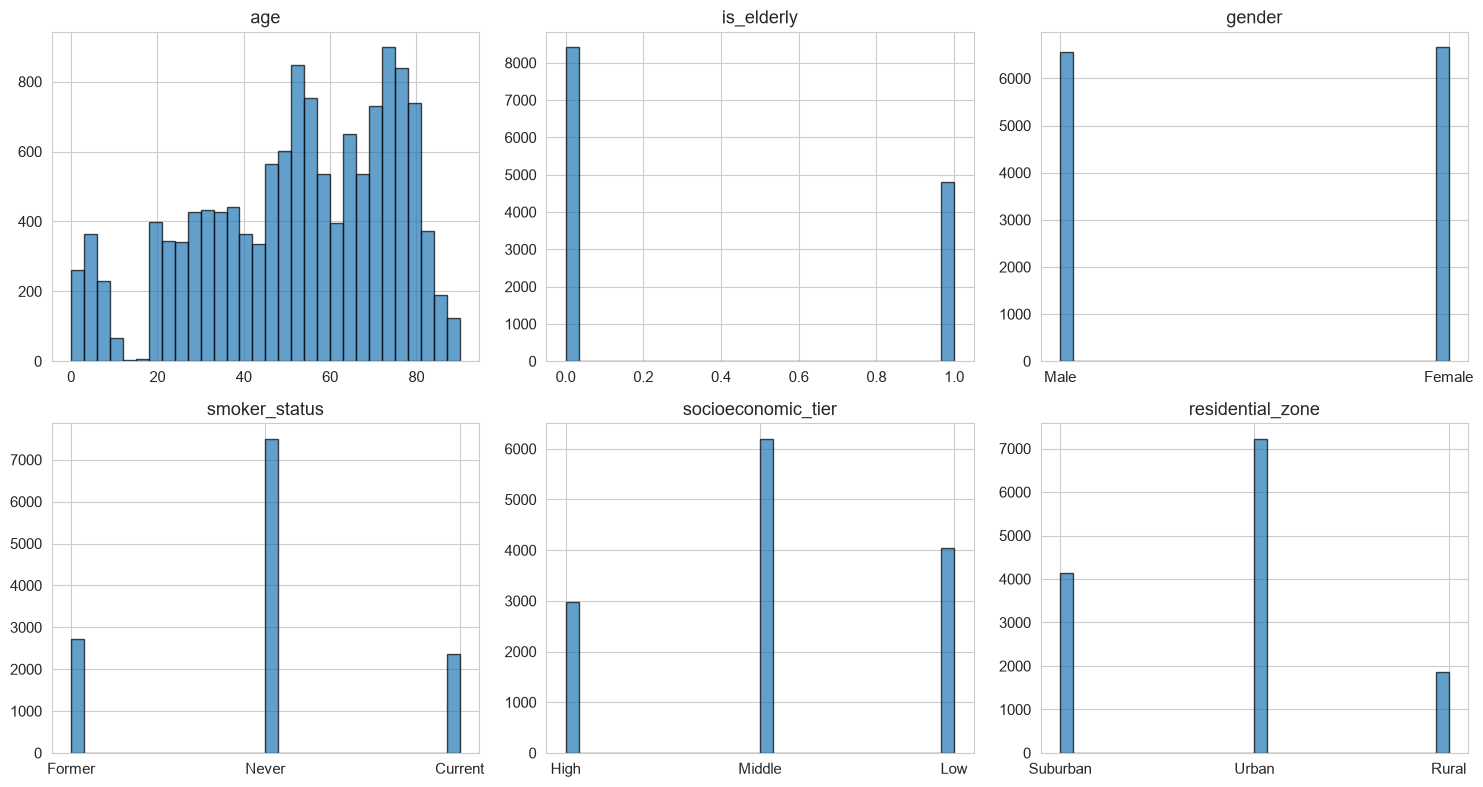

In [40]:
# Histogramas numéricas demografia
num_demo = [c for c in demo_cols if X[c].dtype != 'object']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(num_demo):
    if i < len(axes):
        axes[i].hist(X[col].dropna(), bins=30, alpha=0.7, edgecolor='black')
        axes[i].set_title(col)
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()

### 9.2 Contexto da Internação

In [41]:
enc_cols = ['encounter_type', 'admission_urgency', 'department', 'length_of_stay_days',
            'los_category', 'revisit_count', 'days_since_last_discharge', 'first_admission_flag']
enc_cols = [c for c in enc_cols if c in X.columns]

print('=== ESTATÍSTICAS ===')
print(X[enc_cols].describe(include='all').T)

print('\n=== TARGET RATE ===')
for c in [c for c in enc_cols if X[c].dtype == 'object']:
    print(f'\n--- {c} ---')
    print(pd.crosstab(X[c], y, normalize='index').round(3))

=== ESTATÍSTICAS ===
                             count unique               top  freq        mean         std   min   25%    50%    75%    max
encounter_type               13214      3        Outpatient  5389         NaN         NaN   NaN   NaN    NaN    NaN    NaN
admission_urgency            13214      3          Elective  6423         NaN         NaN   NaN   NaN    NaN    NaN    NaN
department                   13214      8  General Medicine  4918         NaN         NaN   NaN   NaN    NaN    NaN    NaN
length_of_stay_days        13214.0    NaN               NaN   NaN    5.758047    7.055869  0.15  0.33    3.6    8.5   34.0
los_category                 13214      4               0-1  5409         NaN         NaN   NaN   NaN    NaN    NaN    NaN
revisit_count              13214.0    NaN               NaN   NaN    2.275087    1.367611   1.0   1.0    2.0    3.0    6.0
days_since_last_discharge   8214.0    NaN               NaN   NaN  106.582189  103.507973   1.0  10.3  70.35  196.8  3

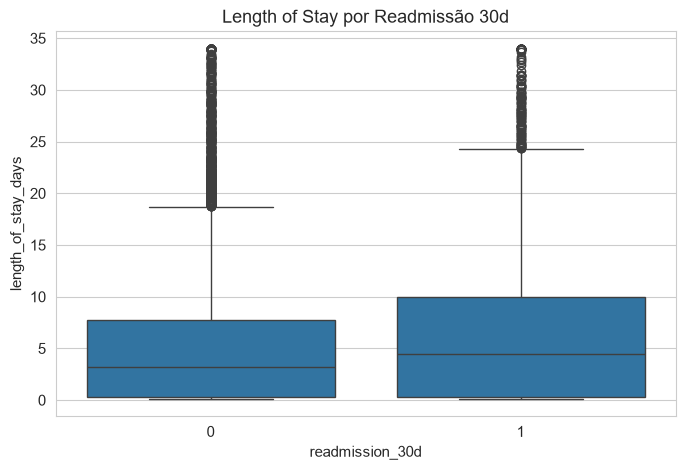

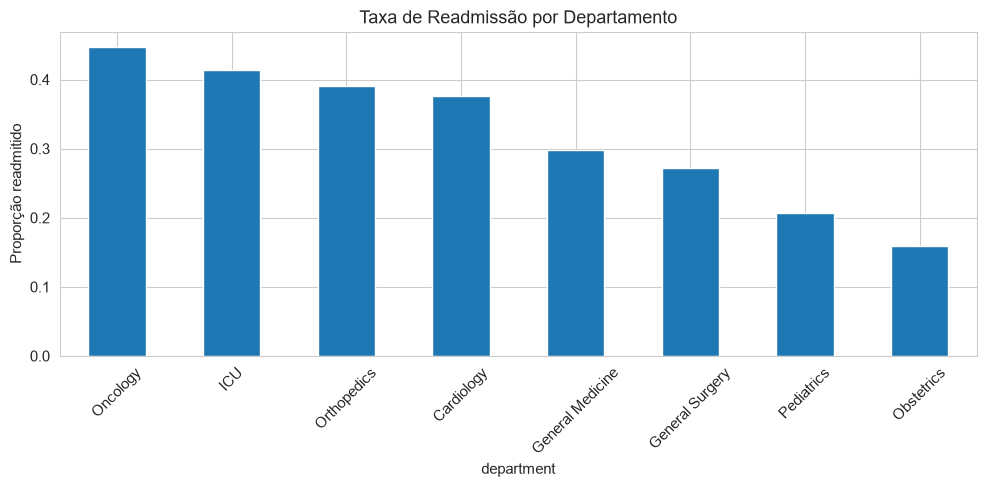

In [42]:
# Boxplot: length_of_stay_days por target
plt.figure(figsize=(8, 5))
sns.boxplot(data=X, x=y, y='length_of_stay_days')
plt.title('Length of Stay por Readmissão 30d')
plt.show()

# Barplot: department por target rate
if 'department' in X.columns:
    dept_rate = pd.crosstab(X['department'], y, normalize='index')[1].sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    dept_rate.plot(kind='bar')
    plt.title('Taxa de Readmissão por Departamento')
    plt.ylabel('Proporção readmitido')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 9.3 Estado Clínico na Alta (Vitais + Labs)

In [43]:
clin_cols = ['systolic_bp', 'diastolic_bp', 'heart_rate', 'respiratory_rate', 'temperature',
             'spo2', 'glucose', 'creatinine', 'hemoglobin', 'wbc_count',
             'disease_category', 'disease_severity']
clin_cols = [c for c in clin_cols if c in X.columns]

print('=== ESTATÍSTICAS ===')
print(X[clin_cols].describe(include='all').T)

print('\n=== TARGET RATE ===')
for c in [c for c in clin_cols if X[c].dtype == 'object']:
    print(f'\n--- {c} ---')
    print(pd.crosstab(X[c], y, normalize='index').round(3))

=== ESTATÍSTICAS ===
                    count unique          top  freq        mean        std   min    25%    50%    75%    max
systolic_bp       13214.0    NaN          NaN   NaN  122.211291  19.055208  68.0  112.9  122.3  131.6  197.8
diastolic_bp      13214.0    NaN          NaN   NaN   80.818571  12.427099  45.0   74.1   80.8   87.6  120.0
heart_rate        13214.0    NaN          NaN   NaN   80.563244  16.990314  55.0   69.7   76.8   85.8  155.0
respiratory_rate  13214.0    NaN          NaN   NaN   17.499213   4.131009  12.0   15.0   16.5   18.4   39.2
temperature       13214.0    NaN          NaN   NaN   36.938527   0.728502  36.0   36.5   36.8   37.1   40.4
spo2              12459.0    NaN          NaN   NaN   96.849924   3.439451  77.9   96.6   97.8   98.8  100.0
glucose           12391.0    NaN          NaN   NaN  112.942652  39.564979  65.0   91.3  104.2  119.0  349.2
creatinine        12459.0    NaN          NaN   NaN    1.592064   0.842431   0.5   0.98   1.29   2.01    7.

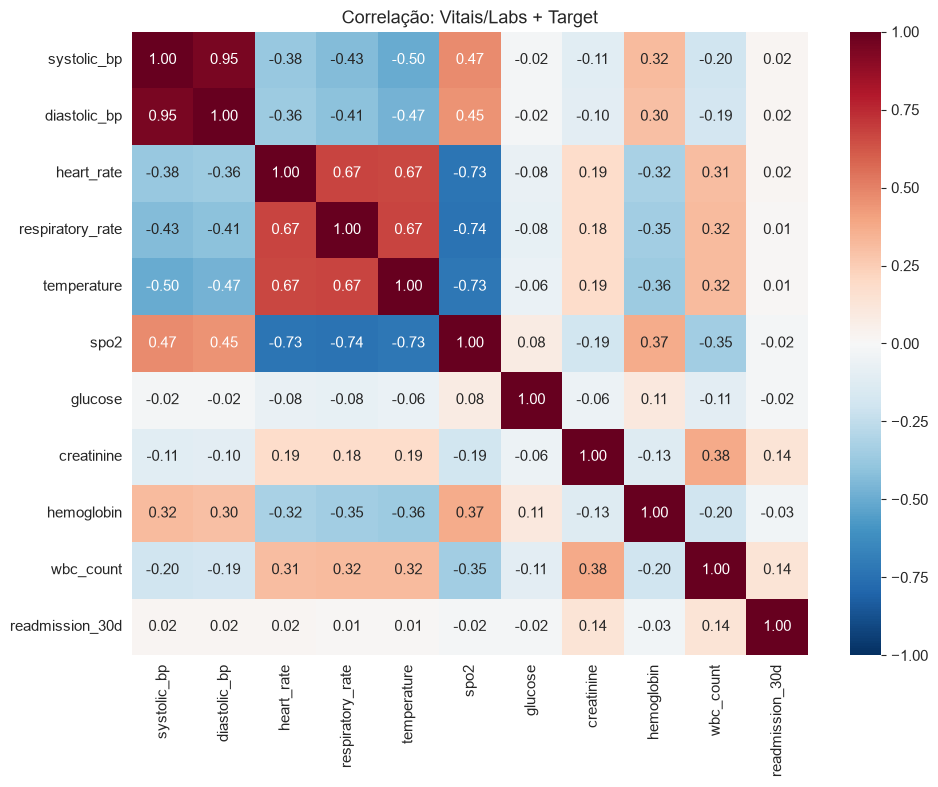

In [44]:
# Heatmap correlação numéricas clínicas com target
num_clin = [
    c for c in clin_cols
    if c in X.columns and pd.api.types.is_numeric_dtype(X[c])
]
if len(num_clin) > 1:
    # O target normalmente está em y, pois foi removido de X.
    if 'y' in globals():
        target = y.rename('readmission_30d')
    else:
        target = df['readmission_30d']
    corr_data = pd.concat([X[num_clin], target], axis=1).corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_data, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
    plt.title('Correlação: Vitais/Labs + Target')
    plt.tight_layout()
    plt.show()

### 9.4 Perfil de Medicação na Alta

In [45]:
med_cols = ['num_medications', 'num_therapeutic_classes', 'polypharmacy_flag',
            'has_high_risk_med', 'has_anticoagulant', 'has_insulin',
            'has_diuretic', 'has_beta_blocker', 'has_ace_arb']
med_cols = [c for c in med_cols if c in X.columns]

print('=== ESTATÍSTICAS ===')
print(X[med_cols].describe(include='all').T)

print('\n=== TARGET RATE ===')
for c in [c for c in med_cols if X[c].dtype == 'object']:
    print(f'\n--- {c} ---')
    print(pd.crosstab(X[c], y, normalize='index').round(3))

=== ESTATÍSTICAS ===
                           count      mean       std  min  25%  50%  75%  max
num_medications          13214.0  2.021719  0.815759  1.0  1.0  2.0  3.0  3.0
num_therapeutic_classes  13214.0  2.021719  0.815759  1.0  1.0  2.0  3.0  3.0
polypharmacy_flag        13214.0  0.000000  0.000000  0.0  0.0  0.0  0.0  0.0
has_high_risk_med        13214.0  0.332450  0.471109  0.0  0.0  0.0  1.0  1.0
has_anticoagulant        13214.0  0.116846  0.321249  0.0  0.0  0.0  0.0  1.0
has_insulin              13214.0  0.067201  0.250380  0.0  0.0  0.0  0.0  1.0
has_diuretic             13214.0  0.054488  0.226986  0.0  0.0  0.0  0.0  1.0
has_beta_blocker         13214.0  0.079158  0.269996  0.0  0.0  0.0  0.0  1.0
has_ace_arb              13214.0  0.079310  0.270232  0.0  0.0  0.0  0.0  1.0

=== TARGET RATE ===


In [46]:
# Target rate por flags de medicação binárias
bin_med = [c for c in med_cols if c in X.columns and X[c].nunique() == 2]
target = y.rename('readmission_30d')
for c in bin_med:
    rate = pd.DataFrame({'feature': X[c], 'target': target}).groupby('feature')['target'].mean()
    print(f'{c}: 0→{rate.get(0,0):.3f}, 1→{rate.get(1,0):.3f}')

has_high_risk_med: 0→0.303, 1→0.385
has_anticoagulant: 0→0.325, 1→0.374
has_insulin: 0→0.332, 1→0.306
has_diuretic: 0→0.328, 1→0.374
has_beta_blocker: 0→0.327, 1→0.362
has_ace_arb: 0→0.324, 1→0.398


## 10. Missingness Analysis

Entender padrões de missing data e decidir estratégia de imputação.

In [47]:
# Missingness detalhado
missing_df = pd.DataFrame({
    'coluna': X.columns,
    'n_missing': X.isnull().sum().values,
    'pct_missing': (X.isnull().mean() * 100).round(2).values,
    'dtype': X.dtypes.values
})
missing_df = missing_df[missing_df['n_missing'] > 0].sort_values('pct_missing', ascending=False)
print(missing_df.to_string(index=False))

# Missing vs target
for col in missing_df['coluna'].head(10):
    X[f'{col}_was_missing'] = X[col].isna().astype(int)
    print(f'{col}_was_missing target rate:')
    print(pd.DataFrame({
        'was_missing': X[f'{col}_was_missing'],
        'target': y
    }).groupby('was_missing')['target'].mean().round(3))
    print()

                   coluna  n_missing  pct_missing   dtype
     procedure_complexity       5654        42.79     str
days_since_last_discharge       5000        37.84 float64
    previous_encounter_id       5000        37.84     str
      insurance_policy_id        987         7.47     str
             baseline_bmi        843         6.38 float64
                  glucose        823         6.23 float64
  emergency_contact_phone        816         6.18     str
                wbc_count        802         6.07 float64
 secondary_diagnosis_code        791         5.99     str
            contact_phone        762         5.77     str
               creatinine        755         5.71 float64
                     spo2        755         5.71 float64
   attending_physician_id        739         5.59     str
               hemoglobin        674         5.10 float64
            smoker_status        647         4.90     str
procedure_complexity_was_missing target rate:
was_missing
0    0.365
1  

## 11. Lista Final de Features para Modelagem

Consolidar as 28 features finais com justificativas.

In [48]:
# Features finais (ordem fixa = ordem do treino)
FEATURES_FINAL = [
    # Demografia (9)
    'age', 'is_elderly', 'gender', 'charlson_comorbidity_index', 'bmi',
    'smoker_status', 'socioeconomic_tier', 'residential_zone', 'marital_status',
    # Internação (8)
    'encounter_type', 'admission_urgency', 'department', 'length_of_stay_days',
    'los_category', 'revisit_count', 'days_since_last_discharge', 'first_admission_flag',
    # Clínico na Alta (11)
    'systolic_bp', 'diastolic_bp', 'heart_rate', 'respiratory_rate', 'temperature',
    'spo2', 'glucose', 'creatinine', 'hemoglobin', 'wbc_count',
    'disease_category', 'disease_severity',
    # Medicações (9)
    'num_medications', 'num_therapeutic_classes', 'polypharmacy_flag',
    'has_high_risk_med', 'has_anticoagulant', 'has_insulin',
    'has_diuretic', 'has_beta_blocker', 'has_ace_arb',
]

# Verificar quais existem
existing = [c for c in FEATURES_FINAL if c in X.columns]
missing = [c for c in FEATURES_FINAL if c not in X.columns]
print(f'Features existentes: {len(existing)}')
print(f'Features faltando: {missing}')

X_final = X[existing].copy()
print(f'X_final shape: {X_final.shape}')

Features existentes: 36
Features faltando: ['charlson_comorbidity_index', 'bmi']
X_final shape: (13214, 36)


## 12. Resumo das Decisões (para README e Apresentação)

| Decisão | Detalhe |
|----------|---------|
| **Variável-alvo** | `readmission_30d` (binária, ~33% positivos) |
| **Features** | 28 features de 4 tabelas joinadas |
| **Vazamento removido** | `discharge_disposition`, `icu_admitted`, `in_hospital_mortality`, billing, IDs, datas |
| **Pré-processamento** | Numéricas: mediana; Categóricas: moda + OneHotEncoder(handle_unknown='ignore') |
| **Modelo** | Pipeline: ColumnTransformer + GaussianNB (maioria numéricas após encoding) |
| **Split** | 80/20 estratificado, random_state=42 |
| **Métricas** | Acurácia, Precision/Recall/F1 macro, AUC-ROC, AUC-PR, Matriz de Confusão |
| **Limitações** | Dataset sintético; vazamento potencial em vitais/meds de alta; NB assume independência |

---

**Próximo passo**: Executar `02_treino.ipynb` para treino, avaliação e exportação do modelo.